# 🐜🐝 Mini proiect · Transfer learning pe propriile imagini

În acest notebook vei adapta un model pre-antrenat la **propriile tale imagini**. Poți clasifica animale, obiecte, plante sau orice altceva pentru care ai cel puțin două clase de imagini.

Vei folosi ResNet18, un model care a învățat deja să recunoască forme și texturi. Tu îi vei schimba ultimul strat ca să învețe clasele proiectului tău.

**Copie explicată (`_02`): what is new in this copy**

A copy of `CNNs_proiect.ipynb`. The course text stays in Romanian; everything added is in English:
- an **English comment under every line of code**, and a **"What this cell does"** note after every code cell, with the real numbers of this run;
- **the project's dataset: 5 kinds of flowers** (daisy, dandelion, roses, sunflowers, tulips): 100 free-licensed photos per class from TensorFlow's `flower_photos` set, split 80 / 20 into 400 training and 100 validation images. The extra cell after the settings downloads and builds it if `CALE_DATE` does not exist yet;
- extras:
  - a fixed seed;
  - a grid of sample images;
  - a **confusion matrix** with recall and precision per class, and the **misclassified images**;
  - the **optional challenge solved**: ResNet18 vs EfficientNet-B0 vs MobileNetV3-Large (feature extraction) and ResNet18 fine-tuning, with accuracy and CPU time.

Runs on CPU in about 5 minutes (312 s, including the one-time 218 MB download; the 4-model comparison is most of the rest) (the comparison is most of it).

## Cum rulezi în Google Colab

1. Deschide notebook-ul în Google Colab. Alege `Runtime` → `Change runtime type` → `T4 GPU` → `Save`.
2. Pregătește imaginile în structura de mai jos. Numele folderelor sunt numele claselor:

```text
/content/proiectul_meu/
├── train/
│   ├── clasa_1/   # aproximativ 80% dintre imagini
│   └── clasa_2/
└── val/
    ├── clasa_1/   # aproximativ 20% dintre imagini
    └── clasa_2/
```

3. Nu pune aceeași imagine în `train` și `val`. Ideal, începe cu 50–100 de imagini pentru fiecare clasă.
4. În Colab, deschide pictograma de folder din stânga și încarcă datele în `/content/`. Dacă folosești Google Drive, montează Drive și folosește o cale care începe cu `/content/drive/MyDrive/`.
5. Completează doar setările din celula marcată **SETĂRI PROIECT**, apoi rulează celulele în ordine.

In [1]:
# Importăm doar bibliotecile necesare pentru acest mini-proiect.
# (the course's comment) only the libraries this mini-project needs
import numpy as np
# numpy: arrays (not used directly by the course cells; used by the extra cells)
import torch
# PyTorch: tensors, gradients, the GPU
import torch.nn as nn
# nn = the neural-network building blocks (layers, loss functions)
import torchvision
# torchvision = PyTorch's computer-vision library
from torchvision import datasets, transforms, models
# datasets.ImageFolder (reads class folders), transforms (resize, crop, normalise), models (pre-trained networks)

# Folosim GPU dacă este disponibil în Colab; altfel folosim procesorul.
# (the course's comment) use the GPU if there is one, otherwise the CPU
device = "cuda" if torch.cuda.is_available() else "cpu"
# "cuda" = NVIDIA GPU; without one, "cpu"
print("Rulăm pe:", device)
# "We run on:" cpu / cuda

Rulăm pe: cpu


**What this cell does:**
- Imports PyTorch and torchvision and picks the device. On a machine without a GPU (as in this run) it prints **`Rulăm pe: cpu`**. In Colab with a T4 GPU it prints `cuda`, and training is ~10–20× faster.

**Extra (this copy) · a repeatable run**

Training uses randomness: the shuffle order, the random crops and flips, and the new layer's starting weights. Fixing the seed makes every run of this notebook give the same numbers, so the notes below match what you see. Remove the cell if you want to see the natural variation between runs.

In [2]:
import random
# Python's own random generator
torch.manual_seed(0)
# fix PyTorch's random numbers (new layer weights, shuffling, random crops/flips)
random.seed(0); np.random.seed(0)
# and Python's / numpy's, for completeness
import matplotlib.pyplot as plt
# plots, for the extra figures
import time
# timing the training runs

**What this cell does:**
- Fixes the random seeds and imports matplotlib and time for the extra cells. On a CPU with `num_workers=0`, this makes the whole run repeatable.

## Funcții ajutătoare

Nu trebuie să modifici codul din celula următoare. Funcțiile se ocupă de antrenare și evaluare, ca `fit()` și `score()` în scikit-learn.

In [3]:
def evalueaza(model, loader):
    # returns the accuracy of `model` on all the images of `loader` ("evaluează" = evaluate)
    # Oprim calculul gradientului: acum doar verificăm modelul.
    # (the course's comment) no gradients now: we only check the model
    model.eval()
    # evaluation mode: dropout off, batch-norm uses its stored statistics
    corecte = 0
    # counter of correct predictions ("corecte" = correct ones)
    total = 0
    # counter of all images

    with torch.no_grad():
        # inside this block PyTorch does not record operations for backward → faster, less memory
        for imagini, etichete in loader:
            # one batch at a time: images (tensor N×3×224×224) and labels (N class numbers)
            imagini = imagini.to(device)
            # move the images to the CPU/GPU where the model is
            etichete = etichete.to(device)
            # and the labels
            predictii = model(imagini).argmax(1)
            # forward pass → one score per class per image; argmax(1) = the class with the highest score
            corecte += (predictii == etichete).sum().item()
            # how many in this batch are right (True = 1); .item() turns the 1-number tensor into a Python int
            total += len(etichete)
            # how many images in this batch

    return corecte / total
    # accuracy = correct / all


def antreneaza(model, train_loader, val_loader, epoci, rata_invatare):
    # the training loop of Sessions 16–19, packed in one function ("antrenează" = train; "epoci" = epochs; "rata de învățare" = learning rate)
    model.to(device)
    # move the model's weights to the device

    # Antrenăm doar parametrii care nu sunt înghețați.
    # (the course's comment) train only the parameters that are not frozen
    parametri_antrenabili = [
        parametru for parametru in model.parameters()
        if parametru.requires_grad
    ]
    # list comprehension: keep only the weights with requires_grad=True (feature extraction → only the new last layer)
    optimizer = torch.optim.Adam(parametri_antrenabili, lr=rata_invatare)
    # Adam: the optimizer that updates those weights, with step size lr
    functie_pierdere = nn.CrossEntropyLoss()
    # the loss for classification: softmax + log loss in one ("funcție de pierdere" = loss function)

    for epoca in range(1, epoci + 1):
        # one epoch = one pass over all the training images
        model.train()
        # training mode (dropout / batch-norm behave as during training)
        suma_pierdere = 0
        # sum of the batch losses of this epoch

        for imagini, etichete in train_loader:
            # one shuffled batch of 16 images
            imagini = imagini.to(device)
            # to the device
            etichete = etichete.to(device)
            # to the device

            optimizer.zero_grad()
            # 1. erase the gradients of the previous batch (PyTorch adds them up otherwise)
            predictii = model(imagini)
            # 2. forward pass: the scores (logits) per class
            pierdere = functie_pierdere(predictii, etichete)
            # 3. how wrong they are ("pierdere" = loss)
            pierdere.backward()
            # 4. backpropagation: the gradient of the loss for every trainable weight
            optimizer.step()
            # 5. move the weights a small step against the gradient
            suma_pierdere += pierdere.item()
            # add this batch's loss (as a Python number)

        acuratete_val = evalueaza(model, val_loader)
        # after each epoch: accuracy on the validation images
        print(
            f"Epoca {epoca}/{epoci} | "
            f"pierdere: {suma_pierdere:.3f} | "
            f"validare: {acuratete_val:.1%}"
        )
        # one line per epoch: epoch, summed training loss, validation accuracy as a percentage

    return model
    # the trained model

**What this cell does:**
- Defines two helpers, so the later cells stay short:
  - **`evalueaza`** = accuracy on a loader. Eval mode, no gradients, argmax per image, correct / total. It is like `score()` in scikit-learn.
  - **`antreneaza`** = the 5-step loop of Session 16, run for several epochs: zero_grad → forward → loss → backward → step. Only parameters with `requires_grad=True` go to Adam, and after every epoch it prints the loss and the validation accuracy. It is like `fit()`.
- Note: the printed "pierdere" is the **sum** of the batch losses, not the mean, so its size depends on how many batches there are.

## Pasul 1 · Setările proiectului

Schimbă doar valorile din zona de mai jos. La prima rulare, păstrează `resnet18` și `feature_extraction`.

In [4]:
# ======== SETĂRI PROIECT: schimbă doar aici ========
# (the course's banner) "PROJECT SETTINGS: change only here"
CALE_DATE = "data/flori"  # folderul care conține train/ și val/
# (changed, was "/content/proiectul_meu") the folder with train/ and val/: our 5-class flower dataset, built by the next cell if it is missing ("cale date" = data path; "flori" = flowers)
ARHITECTURA = "resnet18"             # păstrează această valoare la prima rulare
# the pre-trained network (keep resnet18 for the first run)
STRATEGIE = "feature_extraction"     # apoi poți încerca "fine_tuning"
# feature_extraction = freeze the network, train only the new last layer; "fine_tuning" = train everything (strategy)
EPOCI = 3                              # câte treceri face modelul prin imaginile de train
# how many passes over the training images
# ===================================================

**What this cell does:**
- The only cell you are meant to edit. **Changed:** `CALE_DATE` points to `data/flori`, the project's dataset: 5 kinds of flowers, 100 photos each, split 80 / 20 into `train/` and `val/`. The next cell builds it if it is missing.
- **For your own project:** make a folder with `train/<class>/` and `val/<class>/` subfolders and put its path here. In Colab: `/content/proiectul_meu` or `/content/drive/MyDrive/...`.

**Extra · the project's images: 5 kinds of flowers**

The dataset is TensorFlow's free **flower_photos** set: 3,670 photos from Flickr in 5 folders (daisy, dandelion, roses, sunflowers, tulips), licensed **CC BY 2.0**. Following the course's advice (*50–100 images per class, about 80% train / 20% val, never the same image in both*), the cell below draws a fixed random **100 photos per class** and splits them **80 / 20**: 400 training + 100 validation photos in `data/flori/`.

**Getting the images:**
- **Automatic (recommended):** just run the cell below, in Colab or locally. It downloads the archive once and builds `data/flori/train` and `data/flori/val`.
- **Direct download:** [flower_photos.tgz (218 MB)](https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz). The dataset page is [tensorflow.org/datasets/catalog/tf_flowers](https://www.tensorflow.org/datasets/catalog/tf_flowers).
- **By hand:** unpack the archive into `data/`, so you get `data/flower_photos/<class>/*.jpg`, and run the cell below. It skips the download and only copies the 500 chosen photos. [`flori_split.csv`](flori_split.csv) in the repository lists exactly which 500 photos are used and whether each is in `train` or `val`.

**Credits:** every photo's author and Flickr link are in `flori_split.csv` (for the 500 used here) and in `data/flower_photos/LICENSE.txt` (for all 3,670).

In [5]:
import os, random, shutil, tarfile, urllib.request
# file checks, random choice, copying, .tgz archives, downloads
from pathlib import Path
# handy file paths
if not os.path.isdir(f"{CALE_DATE}/train"):
    # build the dataset only if it does not exist yet (fresh clone, new Colab session)
    os.makedirs("data", exist_ok=True)
    # a local data/ folder (not committed to git)
    arhiva = "data/flower_photos.tgz"
    # where the archive goes ("arhivă" = archive)
    if not os.path.isdir("data/flower_photos") and not os.path.exists(arhiva):
        # neither the unpacked photos nor the archive are there (if you unpacked it by hand, nothing is downloaded)
        urllib.request.urlretrieve("https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz", arhiva)
        # download the official TensorFlow example archive from Google Cloud Storage (~218 MB, once)
    if not os.path.isdir("data/flower_photos"):
        # not unpacked yet
        with tarfile.open(arhiva) as t:
            t.extractall("data", filter="data")
            # unpack → data/flower_photos/<class>/*.jpg (filter="data" = the safe extraction mode)
    rnd = random.Random(42)
    # our own random generator with a fixed seed → always the same 100 photos
    for clasa in sorted(p.name for p in Path("data/flower_photos").iterdir() if p.is_dir()):
        # the 5 class folders, alphabetically
        fisiere = sorted(Path("data/flower_photos", clasa).glob("*.jpg"))
        # all the photos of this class, in a fixed order ("fișiere" = files)
        for k, f in enumerate(rnd.sample(fisiere, 100)):
            # 100 photos drawn at random, without repetition
            dest = Path(CALE_DATE, "train" if k < 80 else "val", clasa)
            # the first 80 → train/, the last 20 → val/: no photo is in both
            dest.mkdir(parents=True, exist_ok=True)
            # create the class folder
            shutil.copy(f, dest / f.name)
            # copy the photo there
for parte in ["train", "val"]:
    # check the result ("parte" = part)
    print(parte, {c.name: len(list(c.glob("*.jpg"))) for c in sorted(Path(CALE_DATE, parte).iterdir())})
    # number of photos per class

train {'daisy': 80, 'dandelion': 80, 'roses': 80, 'sunflowers': 80, 'tulips': 80}
val {'daisy': 20, 'dandelion': 20, 'roses': 20, 'sunflowers': 20, 'tulips': 20}


**What this cell does:**
- **train: 80 photos per class, val: 20 per class**, for daisy, dandelion, roses, sunflowers and tulips: **400 training + 100 validation** images, balanced.
- The draw uses `random.Random(42)`, so the same 500 photos are chosen on every machine. The split happens before anything else, so no photo can be in both `train/` and `val/`.
- Licences: the photos are Creative Commons (Flickr). `data/flower_photos/LICENSE.txt` credits each author. The images are downloaded, not stored in the repository.

## Pasul 2 · Verifică datele

`ImageFolder` citește automat numele folderelor ca nume de clase. Dacă apare o eroare, verifică mai întâi calea și structura folderelor.

In [6]:
date_train = datasets.ImageFolder(f"{CALE_DATE}/train")
# reads train/: every subfolder = one class, every image file inside = one example (no transform yet → PIL images)
date_val = datasets.ImageFolder(f"{CALE_DATE}/val")
# the same for val/

CLASE = date_train.classes
# the class names = the folder names, sorted alphabetically; their position is the label number (0, 1, …) ("clase" = classes)
print("Clase găsite:", CLASE)
# "Classes found:"
print("Imagini pentru antrenare:", len(date_train))
# number of training images
print("Imagini pentru validare:", len(date_val))
# number of validation images

Clase găsite: ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']
Imagini pentru antrenare: 400
Imagini pentru validare: 100


**What this cell does:**
- Found the **5 classes ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']** (alphabetical, so daisy = 0 … tulips = 4), with **400 training** and **100 validation** images.
- 80 training photos per class sits inside the course's "50–100 per class" range.
- `ImageFolder` reads only real image files (jpg, png…); any other file in the folders is ignored.

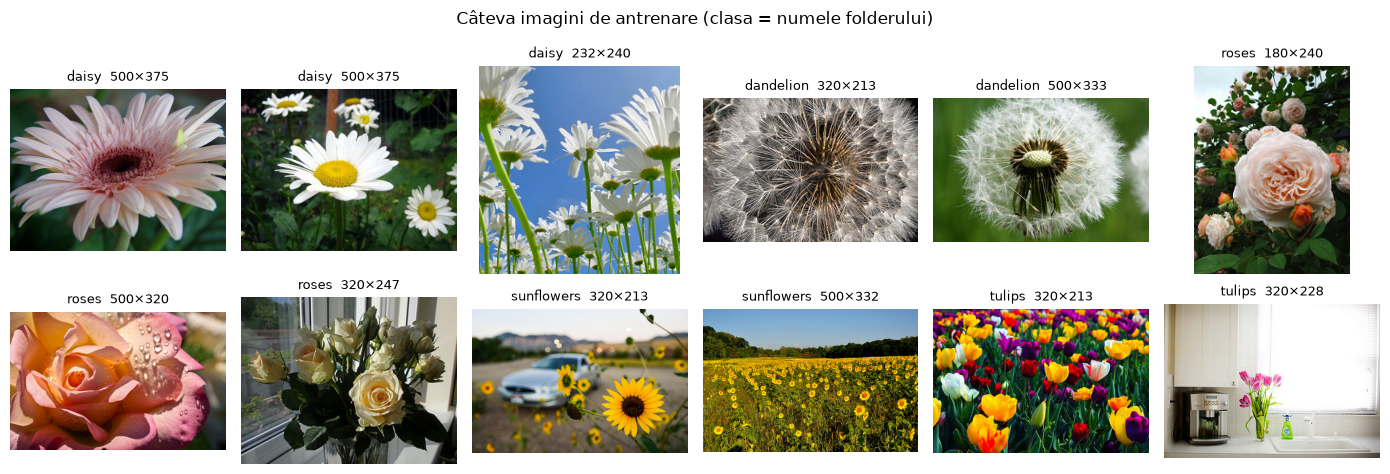

In [7]:
fig, axe = plt.subplots(2, 6, figsize=(14, 5))
# a grid of 2 rows × 6 images ("axe" = axes)
for k, ax in enumerate(axe.flat):
    # 12 panels
    idx = k * (len(date_train) // 12)
    # spread the picks over the whole dataset, so every class appears
    imagine, eticheta = date_train[idx]
    # without a transform, ImageFolder returns a PIL image and its class number
    ax.imshow(imagine)
    # draw the photo as it is on disk
    ax.set_title(f"{CLASE[eticheta]}  {imagine.size[0]}×{imagine.size[1]}", fontsize=9)
    # the class name and the original size
    ax.axis("off")
    # no axis ticks
plt.suptitle("Câteva imagini de antrenare (clasa = numele folderului)")
# figure title
plt.tight_layout(); plt.show()
# draw

**What this cell does:**
- 12 training photos with their class and original size. The sizes differ (180×240 up to 500×375), so the transforms resize everything to 224×224.
- The photos are varied: close-ups, whole fields, bouquets indoors. There is even a **pink gerbera inside "daisy"**: real datasets contain such label noise.

## Pasul 3 · Construiește modelul

Modelul este pre-antrenat pe ImageNet. Înlocuim ultimul strat cu unul care are exact câte ieșiri ai clase în proiect.

In [8]:
greutati = models.get_model_weights(ARHITECTURA).DEFAULT
# the best available pre-trained weights for this architecture (for ResNet18: ImageNet, 1000 classes); they also carry the matching preprocessing ("greutăți" = weights)
model = models.get_model(ARHITECTURA, weights=greutati)
# build the network by name and load those weights (downloaded once, then cached)

# Feature extraction: păstrăm straturile învățate și antrenăm doar capul.
# (the course's comment) feature extraction: keep the learned layers, train only the head
# Fine-tuning: permitem și straturilor modelului să se adapteze.
# (the course's comment) fine-tuning: let the model's layers adapt too
for parametru in model.parameters():
    # every weight tensor of the network
    parametru.requires_grad = (STRATEGIE == "fine_tuning")
    # True only for fine-tuning; for feature extraction all are frozen (False)

# ResNet are ultimul strat în model.fc.
# (the course's comment) ResNet keeps its last layer in model.fc
if hasattr(model, "fc"):
    # does the model have an attribute called "fc" (fully connected)?
    model.fc = nn.Linear(model.fc.in_features, len(CLASE))
    # replace it with a NEW layer: same number of inputs (512 for ResNet18), one output per class; new layers are trainable by default
else:
    # other families
    # EfficientNet și MobileNet au ultimul strat în model.classifier.
    # (the course's comment) EfficientNet and MobileNet keep it in model.classifier
    model.classifier[-1] = nn.Linear(
        model.classifier[-1].in_features, len(CLASE)
    )
    # replace the last element of their classifier block

print(model)
# print the whole architecture (the last line shows the new fc layer)

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_sta

**What this cell does:**
- Loads ResNet18 pre-trained on ImageNet and **freezes** all its weights (feature extraction). It then replaces the final layer `fc` (512 → 1000 ImageNet classes) with a new `Linear(512 → 5)` layer for our classes.
- The new layer is the only trainable part: **2,565** (512 × 5 weights + 5 biases) trainable parameters out of ~11.2 million. That is why it trains fast even on a CPU and needs few images.
- The long printout is the network: conv1 → 4 "layer" blocks of residual blocks → avgpool → **fc**. Look at the last line.

## Pasul 4 · Pregătește imaginile

La antrenare folosim augmentare, pentru ca modelul să vadă imagini ușor diferite. La validare folosim doar transformarea standard a modelului.

In [9]:
transformare_train = transforms.Compose([
    # a chain of transformations applied to every training image, each time it is loaded
    transforms.RandomResizedCrop(224),
    # augmentation: cut a random part (8–100% of the area, varied aspect) and resize it to 224×224
    transforms.RandomHorizontalFlip(),
    # augmentation: mirror the image left↔right with probability 50%
    greutati.transforms(),
    # the model's own preprocessing: resize 256, center-crop 224, to tensor, normalise with the ImageNet mean/std
])

train_dataset = datasets.ImageFolder(
    f"{CALE_DATE}/train", transform=transformare_train
)
# the training images again, this time with the augmenting transform
val_dataset = datasets.ImageFolder(
    f"{CALE_DATE}/val", transform=greutati.transforms()
)
# validation images: only the standard preprocessing, no randomness (a fair, repeatable test)

train_loader = torch.utils.data.DataLoader(
    train_dataset, batch_size=16, shuffle=True
)
# serves the training images in shuffled batches of 16
val_loader = torch.utils.data.DataLoader(
    val_dataset, batch_size=32
)
# validation batches of 32, always in the same order
print("Datele sunt pregătite.")
# "The data is ready."

Datele sunt pregătite.


**What this cell does:**
- **Augmentation** on training images only: a random crop and a random mirror. The model sees a slightly different version of each photo every epoch, so 244 images act like many more and it overfits less.
- `greutati.transforms()` repeats exactly the preprocessing ResNet18 was trained with: size 224 and ImageNet normalisation. Skipping it would feed the network numbers it has never seen (the Session 17–19 rule: *preprocess like the training data*).
- **A side effect worth knowing:** the train chain applies `RandomResizedCrop(224)` and then the model transform resizes to 256 and center-crops 224, so the outer border of each crop is cut off. It works, but `RandomResizedCrop(224)` + `RandomHorizontalFlip()` + `ToTensor()` + `Normalize(...)` would be the cleaner version.

## Pasul 5 · Antrenează și evaluează

Dacă ai puține imagini, începe cu `feature_extraction`. După aceea schimbă `STRATEGIE` în `fine_tuning` și compară rezultatele.

In [10]:
rata_invatare = 1e-3 if STRATEGIE == "feature_extraction" else 1e-4
# learning rate: 0.001 when only the new layer learns, 10× smaller (0.0001) for fine-tuning so the pre-trained weights are only nudged, not destroyed

model = antreneaza(
    model,
    train_loader,
    val_loader,
    epoci=EPOCI,
    rata_invatare=rata_invatare,
)
# train for EPOCI epochs; prints the loss and the validation accuracy after each one

acuratete = evalueaza(model, val_loader)
# the final accuracy on the validation images ("acuratețe" = accuracy)
print(f"Acuratețea finală pe validare: {acuratete:.1%}")
# "Final validation accuracy:" as a percentage

Epoca 1/3 | pierdere: 35.311 | validare: 63.0%


Epoca 2/3 | pierdere: 24.300 | validare: 71.0%


Epoca 3/3 | pierdere: 20.879 | validare: 74.0%


Acuratețea finală pe validare: 74.0%


**What this cell does:**
- 3 epochs of feature extraction on CPU (~36 s):
  - epoch 1: loss 35.3, validation **63%**
  - epoch 2: 24.3 → 71%
  - epoch 3: 20.9 → **74%**
- **Final validation accuracy: 74.0%** (chance level with 5 classes is 20%).
- Both curves are still improving, so 3 epochs is not enough for 5 classes. More epochs, or the stronger candidates in the comparison below, raise it.

**Extra · where does the model go wrong? An explained confusion matrix + the misclassified images**

The recap asks you to look past the accuracy. Here we collect every validation prediction and draw the confusion matrix:
- with **2 classes**, the explained 2×2 matrix (the second class, `CLASE[1]`, is the "positive" one);
- with **more classes**, a k×k matrix. Rows = the real class, columns = the predicted class, the diagonal = correct. Each off-diagonal square reads "really X → predicted Y". **Recall** per class is written right of its row (how many of the real X were found), **precision** under its column (how many predicted X were really X).

Then we show the images it got wrong.

In [11]:
def matrice_confuzie_explicata(y_true, y_pred, pozitiv="pozitiv", negativ="negativ", titlu="Matricea de confuzie"):
    # draws a 2x2 confusion matrix with the definition written inside every square and the metrics around it
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    # turn the inputs into numpy arrays so they can be compared element by element
    TP = int(((y_true == 1) & (y_pred == 1)).sum())
    # True Positive: really positive, predicted positive
    FN = int(((y_true == 1) & (y_pred == 0)).sum())
    # False Negative: really positive, predicted negative (a missed positive)
    FP = int(((y_true == 0) & (y_pred == 1)).sum())
    # False Positive: really negative, predicted positive (a false alarm)
    TN = int(((y_true == 0) & (y_pred == 0)).sum())
    # True Negative: really negative, predicted negative
    total = TP + FN + FP + TN
    # number of predictions

    fig, ax = plt.subplots(figsize=(10, 6))
    # one empty drawing area
    patrate = [(0, 0, TP, "True Positives (TP)", f"real {pozitiv} → prezis {pozitiv}", True),
               (0, 1, FN, "False Negatives (FN)", f"real {pozitiv} → prezis {negativ}", False),
               (1, 0, FP, "False Positives (FP)", f"real {negativ} → prezis {pozitiv}", False),
               (1, 1, TN, "True Negatives (TN)", f"real {negativ} → prezis {negativ}", True)]
    # the 4 squares: (row, column, count, name, meaning, correct?); rows = reality, columns = prediction
    for rand, col, n, nume, sens, corect in patrate:
        # draw each square ("rând" = row)
        ax.add_patch(plt.Rectangle((col, 1 - rand), 1, 1, facecolor="#5b8def" if corect else "#ebe6f0", edgecolor="white", lw=4))
        # blue = correct predictions (the diagonal), light grey = mistakes
        culoare = "white" if corect else "#333333"
        # text colour that stays readable on the square ("culoare" = colour)
        ax.text(col + .5, 1 - rand + .62, f"{n:,}", ha="center", va="center", fontsize=20, fontweight="bold", color=culoare)
        # the count, big
        ax.text(col + .5, 1 - rand + .38, nume, ha="center", va="center", fontsize=12, color=culoare)
        # the definition, e.g. "False Negatives (FN)"
        ax.text(col + .5, 1 - rand + .2, sens, ha="center", va="center", fontsize=9.5, color=culoare, style="italic")
        # what it means in words

    for col, eticheta in [(0, pozitiv), (1, negativ)]:
        # column headers = the prediction ("etichetă" = label)
        ax.text(col + .5, 2.08, eticheta, ha="center", va="bottom", fontsize=12, fontweight="bold")
    ax.text(1, 2.32, "Predicted value (ce spune modelul)", ha="center", va="bottom", fontsize=12)
    # title of the columns
    for rand, eticheta in [(0, pozitiv), (1, negativ)]:
        # row headers = the reality
        ax.text(-.05, 1 - rand + .5, eticheta, ha="right", va="center", fontsize=12, fontweight="bold")
    ax.text(-.55, 1, "Actual value (realitate)", ha="center", va="center", fontsize=12, rotation=90)
    # title of the rows

    def fractie(a, b):
        # safe division: returns 0 instead of crashing when the denominator is 0
        return a / b if b else 0.0
    mici = dict(fontsize=10, va="center")
    # shared text style for the metrics around the matrix
    ax.text(2.06, 1.5, f"Recall (sensitivity)\n= TP / (TP + FN) = {fractie(TP, TP + FN):.3f}", ha="left", **mici)
    # right of the positive row: share of real positives that were caught
    ax.text(2.06, .5, f"Specificity\n= TN / (TN + FP) = {fractie(TN, TN + FP):.3f}", ha="left", **mici)
    # right of the negative row: share of real negatives recognised as negative
    ax.text(.5, -.2, f"Precision\n= TP / (TP + FP) = {fractie(TP, TP + FP):.3f}", ha="center", **mici)
    # under the "predicted positive" column: share of positive predictions that were right
    ax.text(1.5, -.2, f"Negative Predictive Value\n= TN / (TN + FN) = {fractie(TN, TN + FN):.3f}", ha="center", **mici)
    # under the "predicted negative" column: share of negative predictions that were right
    ax.text(-.05, -.2, f"Prevalence\n= (TP + FN) / total\n= {fractie(TP + FN, total):.3f}", ha="right", **mici)
    # bottom-left: share of real positives in the data (= the "always positive" baseline accuracy)
    ax.text(2.06, -.2, f"Accuracy\n= (TP + TN) / total\n= {fractie(TP + TN, total):.3f}", ha="left", fontweight="bold", **mici)
    # bottom-right: share of all predictions that were right

    ax.set_xlim(-.75, 2.95); ax.set_ylim(-.5, 2.55); ax.axis("off")
    # room for the labels around the squares; hide the axes
    ax.set_title(titlu, fontsize=14, pad=4)
    # title of the figure
    plt.show()
    # draw it

**What this cell does:**
- Defines the **explained confusion matrix** helper (the same as in Sessions 14, 16 and 23): the definitions inside the squares, the metrics around it, positive class first.

In [12]:
def matrice_confuzie_multiclasa(y_true, y_pred, clase, titlu="Matricea de confuzie"):
    # a k×k confusion matrix with recall per row and precision per column ("multiclasă" = multi-class)
    k = len(clase)
    # number of classes
    m = np.zeros((k, k), dtype=int)
    # the empty matrix
    np.add.at(m, (y_true, y_pred), 1)
    # +1 in square (real, predicted) for every image
    fig, ax = plt.subplots(figsize=(1.4 * k + 4, 1.1 * k + 2.5))
    # the figure, sized to the number of classes
    ax.imshow(m, cmap="Blues")
    # darker blue = more images
    for i in range(k):
        for j in range(k):
            ax.text(j, i, m[i, j], ha="center", va="center", fontsize=13, fontweight="bold" if i == j else "normal",
                    color="white" if m[i, j] > m.max() / 2 else "#333333")
            # the count in every square; the diagonal (correct) in bold
    ax.set_xticks(range(k), clase, rotation=30, ha="right"); ax.set_yticks(range(k), clase)
    # class names on both axes
    ax.set_xlabel("Predicted value (ce spune modelul)"); ax.set_ylabel("Actual value (realitate)")
    # axis titles
    for i in range(k):
        ax.text(k - 0.35, i, f"recall {m[i, i] / max(m[i].sum(), 1):.2f}", va="center", fontsize=9)
        # recall = correct / all real images of the class (right of the row)
    for j in range(k):
        ax.text(j, k - 0.3, f"precision\n{m[j, j] / max(m[:, j].sum(), 1):.2f}", ha="center", va="top", fontsize=8)
        # precision = correct / all predictions of the class (under the column)
    ax.set_xlim(-0.5, k + 0.7); ax.set_ylim(k + 0.45, -0.5)
    # room for the texts
    ax.set_title(f"{titlu}\naccuracy = diagonala / total = {np.trace(m)}/{m.sum()} = {np.trace(m) / m.sum():.3f}")
    # the title with the overall accuracy
    plt.tight_layout(); plt.show()
    # draw it

**What this cell does:**
- Defines the **multi-class confusion matrix**: counts in every square (the diagonal in bold), recall for each real class on the right, precision for each predicted class underneath, and the accuracy in the title.

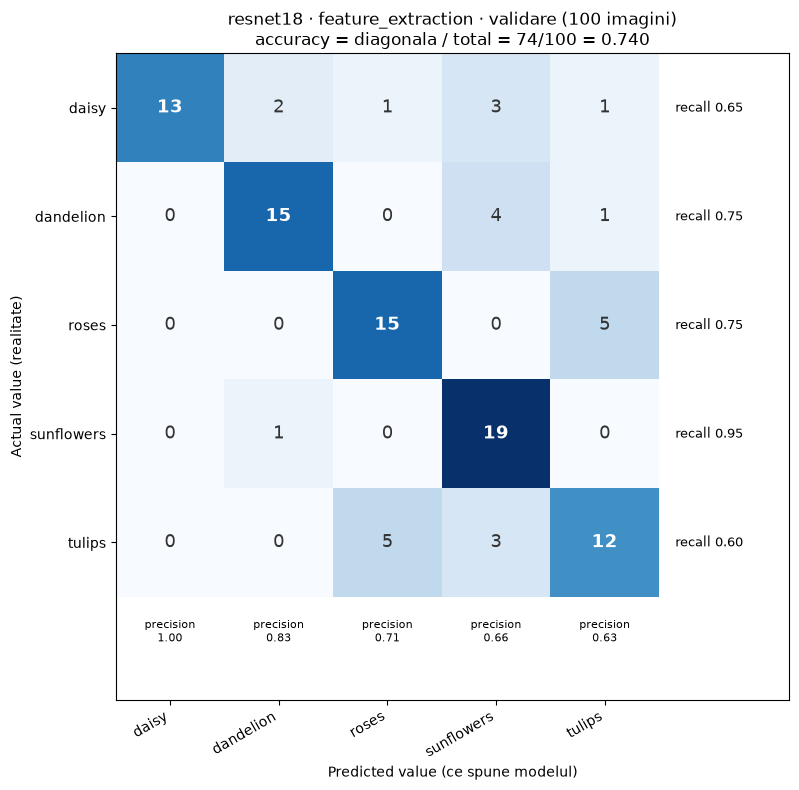

In [13]:
model.eval()
# evaluation mode
toate_pred, toate_real, toate_prob = [], [], []
# predictions, real labels and the probability of the predicted class, for every validation image
with torch.no_grad():
    # no gradients
    for imagini, etichete in val_loader:
        # the validation batches, always in the same order
        scoruri = model(imagini.to(device)).softmax(1)
        # class probabilities (softmax over the scores)
        toate_prob += scoruri.max(1).values.tolist()
        # the confidence of the winning class
        toate_pred += scoruri.argmax(1).tolist()
        # the predicted class
        toate_real += etichete.tolist()
        # the real class
y_real, y_pred = np.array(toate_real), np.array(toate_pred)
# as numpy arrays
if len(CLASE) == 2:
    # the helper draws a 2×2 matrix
    matrice_confuzie_explicata(y_real, y_pred, pozitiv=CLASE[1], negativ=CLASE[0],
                               titlu=f"{ARHITECTURA} · {STRATEGIE} · validare ({len(y_real)} imagini)")
    # rows = truth, columns = prediction; label 1 (CLASE[1]) is the positive class
else:
    # 3 or more classes
    matrice_confuzie_multiclasa(y_real, y_pred, CLASE, titlu=f"{ARHITECTURA} · {STRATEGIE} · validare ({len(y_real)} imagini)")
    # the k×k version

**What this cell does:**
- The 5×5 matrix: **74 of 100** on the diagonal.
  - **sunflowers** are almost always found (recall **0.95**), but they also attract mistakes from other classes (precision **0.66**): 3 daisies and 4 dandelions were called sunflowers. All three have a round yellow centre or yellow petals.
  - **tulips ↔ roses** are mixed up both ways (5 + 5): similar colours and cup-shaped petals. Tulips have the lowest recall (**0.60**).
  - **daisy** has precision **1.00** (whatever it calls a daisy is one), but recall only 0.65: daisies are lost to sunflowers, dandelions, roses and tulips.
- The mistakes follow visual similarity (colour, the round centre), not randomness. That is what a confusion matrix shows and an accuracy number hides.

26 imagini greșite din 100


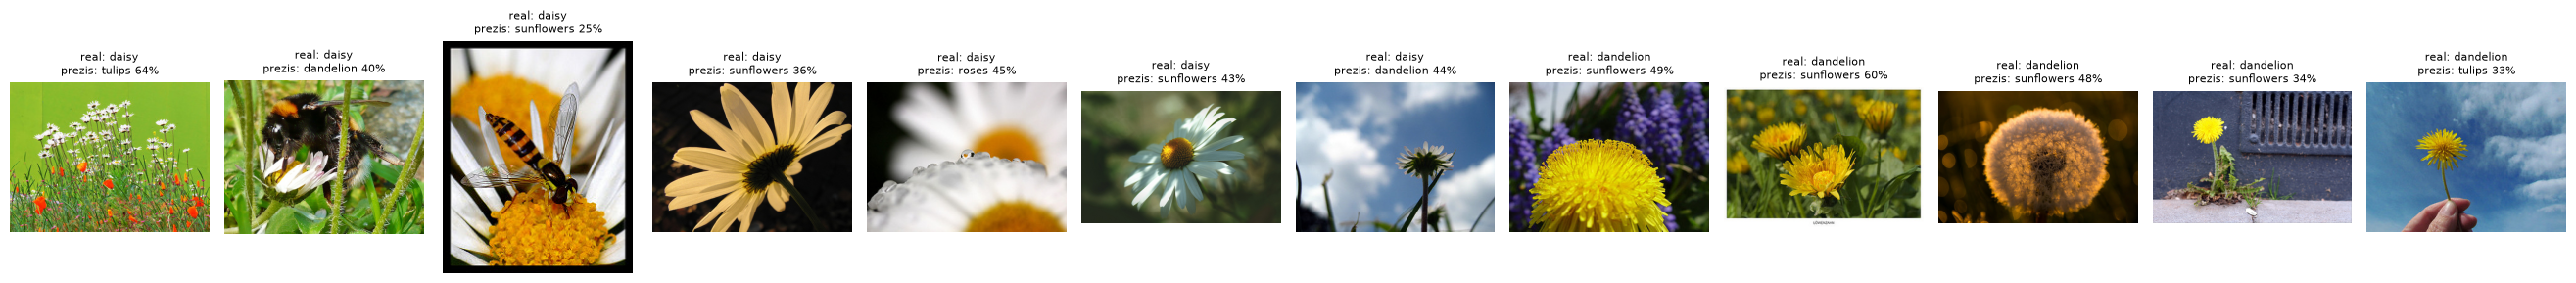

In [14]:
gresite = np.where(y_real != y_pred)[0]
# positions of the misclassified validation images ("greșite" = wrong ones)
print(len(gresite), "imagini greșite din", len(y_real))
# how many
n = min(len(gresite), 12)
# show at most 12
if n:
    fig, axe = plt.subplots(1, n, figsize=(2.2 * n, 2.8), squeeze=False)
    # one row of panels
    for ax, i in zip(axe[0], gresite[:n]):
        # each wrong image
        cale, _ = val_dataset.samples[i]
        # its file path (samples = list of (path, label) in loader order)
        ax.imshow(plt.imread(cale))
        # the original photo
        ax.set_title(f"real: {CLASE[y_real[i]]}\nprezis: {CLASE[y_pred[i]]} {toate_prob[i]:.0%}", fontsize=8)
        # truth, prediction and how sure the model was
        ax.axis("off")
    plt.tight_layout(); plt.show()
    # draw

**What this cell does:**
- 26 wrong out of 100. The 12 shown are the first in validation order (daisies and dandelions), and most have **low confidence** (25–49%): the model was unsure.
- Typical causes visible here:
  - a **bumblebee or a hoverfly** covers most of the daisy;
  - **extreme close-ups** of the yellow centre look like a sunflower;
  - a **dandelion seed head** (the white "clock") looks nothing like a yellow dandelion;
  - a small flower against the sky;
  - a field with mixed flowers and poppies.
- For a real project: add more examples of the hard cases (close-ups, seed heads, insects) to `train/`.

## Provocare opțională

Schimbă `ARHITECTURA` în `"efficientnet_b0"` sau `"mobilenet_v3_large"` și rulează din nou de la Pasul 3. Compară acuratețea și timpul de antrenare cu ResNet18.

> ✍️ Ce arhitectură ai alege pentru proiectul tău și de ce?
>
> *(Based on the comparison in the extra cells below.)* For this flower project I would choose **ResNet18 with fine-tuning**: it reached the best validation accuracy (**86%** vs 74% with the frozen layers), and 76 s of training on a CPU is still cheap.
> - If speed or model size mattered (a phone app, a CPU server), I would pick **MobileNetV3-Large**: 84% with the layers frozen, in 30 s, with 4.2 M parameters instead of 11.2 M. The 2-point gap is only 2 validation images.
> - The next step would be the same comparison with more epochs, because all four models were still improving at epoch 3.

**Extra · the optional challenge, solved: 3 architectures × feature extraction, plus ResNet18 fine-tuning**

The same data, the same 3 epochs, the same seed. Each architecture gets its own preprocessing (`weights.transforms()`), as the course does. Timings are for a laptop CPU (Docker, no GPU); on a Colab T4 GPU everything is much faster.

In [15]:
def ruleaza(arhitectura, strategie, epoci=EPOCI):
    # builds, trains and times one model (steps 3–5 in one function) ("rulează" = run)
    torch.manual_seed(0)
    # the same randomness for every candidate → a fair comparison
    w = models.get_model_weights(arhitectura).DEFAULT
    # pre-trained weights + their preprocessing
    m = models.get_model(arhitectura, weights=w)
    # the network
    for p in m.parameters():
        p.requires_grad = (strategie == "fine_tuning")
        # freeze (feature extraction) or not (fine-tuning)
    if hasattr(m, "fc"):
        m.fc = nn.Linear(m.fc.in_features, len(CLASE))
        # ResNet head
    else:
        m.classifier[-1] = nn.Linear(m.classifier[-1].in_features, len(CLASE))
        # EfficientNet / MobileNet head
    t_train = transforms.Compose([transforms.RandomResizedCrop(224), transforms.RandomHorizontalFlip(), w.transforms()])
    # the course's training transform, with THIS model's preprocessing
    tl = torch.utils.data.DataLoader(datasets.ImageFolder(f"{CALE_DATE}/train", transform=t_train), batch_size=16, shuffle=True)
    # training loader
    vl = torch.utils.data.DataLoader(datasets.ImageFolder(f"{CALE_DATE}/val", transform=w.transforms()), batch_size=32)
    # validation loader
    t0 = time.time()
    # start the clock
    m = antreneaza(m, tl, vl, epoci=epoci, rata_invatare=1e-3 if strategie == "feature_extraction" else 1e-4)
    # the course's training function
    secunde = time.time() - t0
    # training time (incl. the per-epoch validation)
    return {"arhitectura": arhitectura, "strategie": strategie,
            "parametri (mil.)": round(sum(p.numel() for p in m.parameters()) / 1e6, 1),
            "antrenabili": sum(p.numel() for p in m.parameters() if p.requires_grad),
            "acuratete_val": round(evalueaza(m, vl), 3), "secunde": round(secunde)}
    # one result row

rezultate = []
# the comparison table
for arh, strat in [("resnet18", "feature_extraction"), ("efficientnet_b0", "feature_extraction"),
                   ("mobilenet_v3_large", "feature_extraction"), ("resnet18", "fine_tuning")]:
    # the 4 candidates
    print(f"--- {arh} · {strat}")
    # header for this run's epoch lines
    rezultate.append(ruleaza(arh, strat))
    # train and record
import pandas as pd
# tables
comparatie = pd.DataFrame(rezultate)
# the results as a table ("comparație" = comparison)
comparatie
# show it

--- resnet18 · feature_extraction


Epoca 1/3 | pierdere: 35.311 | validare: 63.0%


Epoca 2/3 | pierdere: 24.300 | validare: 71.0%


Epoca 3/3 | pierdere: 20.879 | validare: 74.0%


--- efficientnet_b0 · feature_extraction


Epoca 1/3 | pierdere: 34.614 | validare: 71.0%


... (7 outputs left out)

Epoca 1/3 | pierdere: 23.577 | validare: 81.0%


Epoca 2/3 | pierdere: 11.060 | validare: 85.0%


Epoca 3/3 | pierdere: 8.024 | validare: 86.0%


,arhitectura,strategie,parametri (mil.),antrenabili,acuratete_val,secunde
0,resnet18,feature_extraction,11.2,2565,0.74,36
1,efficientnet_b0,feature_extraction,4.0,6405,0.80,44
2,mobilenet_v3_large,feature_extraction,4.2,6405,0.84,30
3,resnet18,fine_tuning,11.2,11179077,0.86,76


**What this cell does:**
- Same data, 3 epochs, the same seed:

| model | strategy | parameters | trainable | val. accuracy | CPU time |
|---|---|---|---|---|---|
| ResNet18 | feature extraction | 11.2 M | 2,565 | 74% | 36 s |
| EfficientNet-B0 | feature extraction | 4.0 M | 6,405 | 80% | 44 s |
| MobileNetV3-Large | feature extraction | 4.2 M | 6,405 | 84% | **30 s** |
| **ResNet18** | **fine-tuning** | 11.2 M | 11,179,077 | **86%** | 76 s |

- **Fine-tuning helps most:** ResNet18 goes from 74% to **86%** when all its layers adapt (lr 1e-4). It takes ~2× the time.
- **MobileNetV3-Large is the best frozen model** (84%) and the fastest (30 s). Its newer ImageNet features separate the flowers better than ResNet18's.
- Every run was **still improving at epoch 3**, so all four would gain from more epochs.
- **Caveat:** 100 validation images means 1 image = 1 point, and this is a single seed. 84% vs 86% is 2 images, too close to call; 74% vs 86% is a real difference.

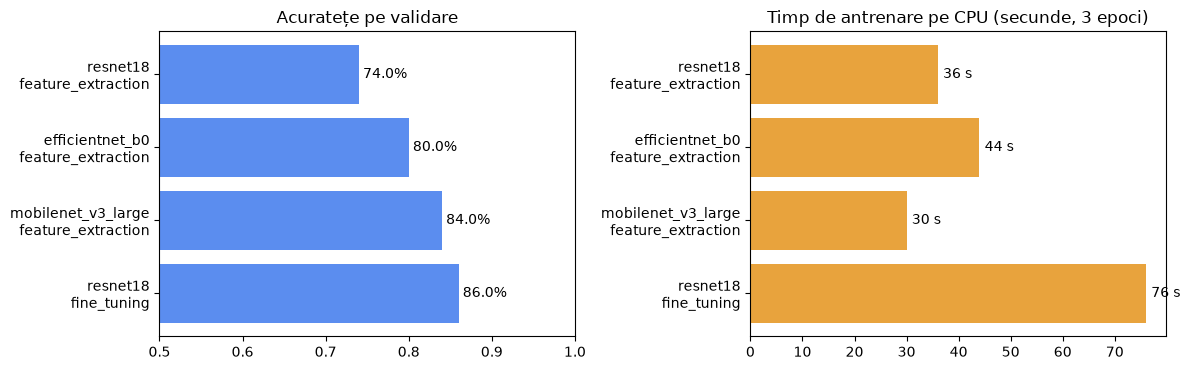

In [16]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.8))
# two charts side by side
etichete_bare = comparatie["arhitectura"] + "\n" + comparatie["strategie"]
# one label per bar: architecture + strategy
ax1.barh(etichete_bare, comparatie["acuratete_val"], color="#5b8def")
# validation accuracy
ax1.set_xlim(0.5, 1); ax1.set_title("Acuratețe pe validare"); ax1.invert_yaxis()
# zoom on 50–100%; the first candidate on top
for y, v in enumerate(comparatie["acuratete_val"]):
    ax1.text(v + 0.005, y, f"{v:.1%}", va="center")
    # the value next to each bar
ax2.barh(etichete_bare, comparatie["secunde"], color="#e8a33d")
# training time
ax2.set_title("Timp de antrenare pe CPU (secunde, 3 epoci)"); ax2.invert_yaxis()
# same order
for y, v in enumerate(comparatie["secunde"]):
    ax2.text(v + 1, y, f"{v} s", va="center")
    # the value next to each bar
plt.tight_layout(); plt.show()
# draw

**What this cell does:**
- Left: validation accuracy (fine-tuned ResNet18 86% > MobileNetV3-Large 84% > EfficientNet-B0 80% > ResNet18 feature extraction 74%). Right: CPU training time for 3 epochs (30–76 s). Fine-tuning buys the extra points with time; MobileNet gives almost the same accuracy for less than half of it.

## Recapitulare

- Datele trebuie organizate în `train/` și `val/`, cu un folder pentru fiecare clasă.
- `feature_extraction` antrenează doar ultimul strat și este un punct bun de pornire pentru seturi mici.
- `fine_tuning` permite și straturilor modelului să se adapteze, folosind o rată de învățare mai mică.
- Acuratețea este doar începutul: verifică și imaginile clasificate greșit înainte să alegi modelul final.